# Weight-Space Programming on a Small Classifier

## 1. Weight-space programming

*Sparks of Weight-Space Programming: LLMs can natively read & write neural network weights* (Takehi, Teoh, Zhang, Khattab, MIT CSAIL; blog post, Nov 2026) claims that a frontier LLM can read and write neural-network weights directly, with no gradients. In their main result, the LLM got the rules and source code of MinAtar games, but no data or gameplay, and wrote a policy network's weights in one reply that beat a PPO-trained baseline. [Post](https://rikiyat.github.io/blog/weight-space-programming/) · [Logs](https://github.com/RikiyaT/lm_understand-logs)

## 2. Objective

Test whether this carries over from games to a small tabular classifier, in two ways: **writing** every weight of a network from scratch, and **editing** a network trained with gradient descent.

## 3. Hypothesis

Weight-space programming carries knowledge into weights. An LLM that knows how the data works can compile that knowledge into a working network without seeing any data; an LLM that doesn't know it cannot. We test this by running every LLM arm twice: **rule known** and **rule not known**.

## 4. Methodology

| Arm | What it gets | Rule known | Rule not known |
|---|---|---|---|
| 1. GD | Training data (Adam + early stopping on validation) | same model | same model |
| 2. AI from scratch | Task, feature names, architecture. **No data, no feedback.** Writes all 513 weights in one reply. | + the exact rule | – |
| 3. GD → AI tweak | The same, plus the GD weights and their train/val metrics. Edits weights over **10 rounds**, one validation forward pass per round. | + the exact rule | – |

- **LLM:** Claude Opus 5.5 (`claude-opus-5-5`, effort `high`) through headless Claude Code (`claude -p`). Each call is isolated: empty working directory, no tools, no MCP servers, a one-line system prompt, no saved session. Weights go in and out as JSON; no LLM-written code is run.
- **Temperature scaling (TS):** every final model is also reported after fitting one temperature on validation log loss (`wsp/model.py:temperature_scale`). It changes only log loss, not accuracy or AUC, so it shows how much of a log-loss gain is plain calibration.
- **Test set:** used once, in section 5, for every model.
- **Logs:** every prompt and reply is saved in `logs/` (rule known) and `logs/norule/` (rule not known), and replayed when the notebook runs, so results can be checked without calling the model.
- **Seeds:** 3 GD seeds; 3 trials of arm 2; arm 3 run once per GD seed. Results are mean ± std.

### 4.1 Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, log_loss

from wsp.data import load_splits, TASK, RULE, FEATURE_NAMES
from wsp.model import N_PARAMS, metrics, temperature_scale
from wsp.gd import train_gd, save_gd, load_gd
from wsp.arm2 import run_arm2
from wsp.arm3 import run_arm3
from wsp.llm import MODEL

SEEDS = [0, 1, 2]
RETRAIN_GD = False  # False = load saved weights from results/gd/
CONDITIONS = {"rule known": True, "rule not known": False}
pd.set_option("display.precision", 3)

### 4.2 Data: synthetic, in an invented domain

**Task (fictional):** predict whether a batch of *velmorite* crystals fails a stress test. Ten true properties of each batch are each measured three ways (`_mean`, `_peak`, `_spread`), giving 30 features; 569 rows, about a third failing (y = 1). Stratified 60/20/20 split, standardized with training-set statistics only. Because the domain is invented, the model cannot have seen this data.

**The rule** (`wsp/data.py`): failure depends on five of the ten properties, with three straight effects, a threshold (`anneal_temp` above +1 SD) and an interaction (`impurity_ratio × cooling_rate`), plus label noise. The features are noisy measurements of the true properties.

With **rule known**, the LLM gets this rule verbatim (printed below), the classifier version of giving the game rules and source code. With **rule not known**, it gets only the task and feature names.

In [2]:
print(TASK); print(); print(RULE); print(); print(FEATURE_NAMES)

Task: predict whether a batch of velmorite crystals fails a stress test. Ten properties of each batch are measured three ways: _mean (average over samples), _peak (maximum over samples) and _spread (variability over samples). Label y = 1 means the batch **fails**, y = 0 means it passes; the model outputs P(y = 1).

How the data is generated (exact):
- Each batch has 10 true properties, each independently standard normal (mean 0, sd 1).
- Failure logit = 1.4*impurity_ratio + 0.9*grain_spread - 1.1*lattice_density + 3.5*max(anneal_temp - 1, 0) + 2.0*impurity_ratio*cooling_rate - 1.3, using the TRUE properties.
- y = 1 (fail) if logit + 0.2*e > 0, where e is standard logistic noise. The other 5 properties do not affect the label.
- Measurements of true property z, each with its own independent standard normal noise n: _mean = z + 0.15*n; _peak = 0.9*z + 0.45*n + 1.5; _spread = 0.4*z + 0.9*n + 3.0.
- About a third of batches fail.

['lattice_density_mean', 'grain_spread_mean', 'impurity_ra

In [3]:
d = load_splits()
pd.DataFrame({"split": ["train", "val", "test"],
              "n": [len(d.y_train), len(d.y_val), len(d.y_test)],
              "failure rate": [d.y_train.mean(), d.y_val.mean(), d.y_test.mean()]})

,split,n,failure rate
0,train,341,0.334
1,val,114,0.333
2,test,114,0.333


### 4.3 Model

MLP 30 → 16 (ReLU) → 1 (sigmoid), 513 parameters, in sklearn's `MLPClassifier` layout. Every arm is scored by the same numpy forward pass (`wsp/model.py`).

### 4.4 Arm 1: GD

Adam (lr 1e-3, batch 32, L2 1e-4), one epoch at a time, early stopping on validation loss (patience 20), keeping the best epoch.

In [4]:
gd = {}
for s in SEEDS:
    try:
        if RETRAIN_GD:
            raise FileNotFoundError
        gd[s] = load_gd(s)
    except FileNotFoundError:
        gd[s] = train_gd(d, s)
        save_gd(gd[s])

pd.DataFrame([{"seed": s, "best_epoch": r["best_epoch"],
               **{f"train_{k}": v for k, v in r["train"].items()},
               **{f"val_{k}": v for k, v in r["val"].items()}} for s, r in gd.items()]).set_index("seed")

,best_epoch,train_loss,train_acc,train_f1,train_auc,val_loss,val_acc,val_f1,val_auc
seed,,,,,,,,,
0,131,0.146,0.962,0.944,0.995,0.379,0.868,0.795,0.908
1,102,0.131,0.977,0.965,0.997,0.307,0.877,0.800,0.929
2,142,0.074,0.994,0.991,1.000,0.288,0.895,0.833,0.941


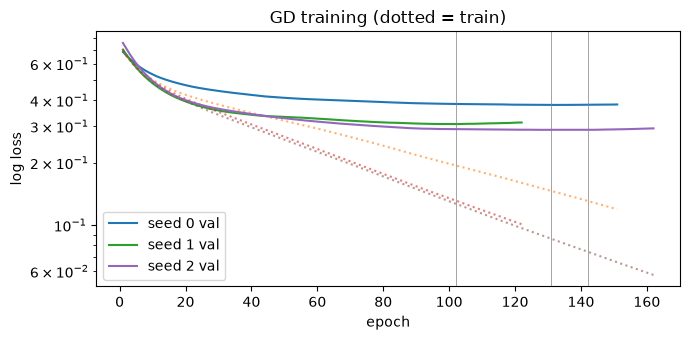

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for s, r in gd.items():
    ep = [h["epoch"] for h in r["history"]]
    ax.plot(ep, [h["val"]["loss"] for h in r["history"]], label=f"seed {s} val")
    ax.plot(ep, [h["train"]["loss"] for h in r["history"]], ls=":", alpha=0.6)
    ax.axvline(r["best_epoch"], color="grey", lw=0.5)
ax.set(xlabel="epoch", ylabel="log loss", yscale="log", title="GD training (dotted = train)")
ax.legend(); plt.tight_layout()

### 4.5 Arm 2: AI from scratch

One reply per trial, 3 trials per condition (`wsp/arm2.py`).

In [6]:
arm2 = {c: [run_arm2(d, t, rule) for t in SEEDS] for c, rule in CONDITIONS.items()}
print("model:", MODEL)
pd.DataFrame([{"condition": c, "trial": r["trial"], **{f"val_{k}": v for k, v in r["val"].items()},
               "out_tokens": r["output_tokens"], "cost_usd": r["cost_usd"], "wall_s": r["wall_s"]}
              for c, runs in arm2.items() for r in runs]).set_index(["condition", "trial"])

model: claude-opus-5-5


val_loss  val_acc  val_f1  val_auc  out_tokens  \
condition      trial                                                   
rule known     0         0.189    0.982   0.974    0.996        4842   
               1         0.191    0.982   0.974    0.996        5206   
               2         0.110    0.974   0.961    0.994        5586   
rule not known 0         0.626    0.667   0.612    0.805        3553   
               1         0.653    0.640   0.577    0.762        3616   
               2         0.679    0.605   0.554    0.760        2719   

                      cost_usd  wall_s  
condition      trial                    
rule known     0         0.100  43.793  
               1         0.107  48.675  
               2         0.115  49.549  
rule not known 0         0.081  32.134  
               1         0.075  30.688  
               2         0.057  25.840

**How it wrote the weights (rule known, trial 0).** The reasoning from the reply; the weights JSON is omitted:

In [7]:
text = json.load(open("logs/arm2_trial0.json"))["text"]
print(text[: text.find("```json")])

**Approach**

I used only the `_mean` features (indices 0–4). Each one is z + 0.15n, so its correlation with the true property is about 0.99. The `_peak` and `_spread` features are much noisier and get zero weight. After z-scoring, each `_mean` feature is close to the true property. I then built each term of the failure logit directly in the hidden layer.

1. **Linear part.** Let s = 1.4·impurity + 0.9·grain − 1.1·lattice. Two units compute relu(s) and relu(−s). Output weights of +1 and −1 give back s exactly.
2. **Hinge term.** One unit computes relu(anneal − 1), with output weight 3.5.
3. **Product term.** I used the identity 2·I·C = ½[(I+C)² − (I−C)²].
   - Each square is approximated by a symmetric piecewise-linear function with knots at |u| = 0, 1.5 and 3.
   - The slopes are 1.5, 4.5 and 7.5, which interpolate u² exactly at 0, 1.5, 3 and 4.5.
   - This uses 6 ReLUs per square: relu(±u), relu(±u − 1.5) and relu(±u − 3).
   - The output weights include the ½ factor, giving 0.75, 1.

**Rule not known, trial 0:**

In [8]:
text = json.load(open("logs/norule/arm2_trial0.json"))["text"]
print(text[: text.find("```json")])

## Approach

There is no data, so these weights come entirely from physical priors about what makes a crystal batch fail under stress. They are a guess, not a fitted model.

**Assumed directions:**
- **Raises failure risk:**
  - impurity ratio (strongest)
  - cooling rate (thermal-shock stress)
  - grain spread (non-uniform microstructure)
  - hydration
  - edge curvature (stress concentration)
  - lattice-density spread
- **Lowers failure risk:** lattice density (mean, and peak to a lesser degree).
- **Anneal temperature:** U-shaped. Batches that are under- or over-annealed both fail more.
- **Treated as irrelevant:** facet count, luminance and isotope shift get zero weight.
- **Weighting of the three measurements:** `_mean` gets the most weight, `_peak` less, and `_spread` a small amount in the "bad" direction. Inconsistent batches tend to be weaker.

**How the network is built:**
- **Hidden units 0–9** come in ± pairs, relu(s) and relu(−s), with output weights +1 and −1. Each pair p

### 4.6 Arm 3: GD → AI tweak

Each GD model is edited over 10 rounds (`wsp/arm3.py`). **One round = one LLM call + one forward pass on the validation set.** Each call is stateless: the prompt carries the task, the GD train/val metrics, the best weights so far (4 d.p.) and a table of every earlier attempt with its validation result and the LLM's one-line note. The LLM replies with single-weight edits as JSON; the model with the lowest validation loss so far is kept.

In [9]:
arm3 = {c: {s: run_arm3(d, gd[s], rule=rule) for s in SEEDS} for c, rule in CONDITIONS.items()}
pd.DataFrame([{"condition": c, "seed": s, "GD val_loss": gd[s]["val"]["loss"], "best val_loss": r["val"]["loss"],
               "val_acc GD → AI": f'{gd[s]["val"]["acc"]:.3f} → {r["val"]["acc"]:.3f}',
               "weights changed": f'{r["n_changed_total"]} / {N_PARAMS}',
               "invalid replies": sum(bool(h["error"]) for h in r["history"]),
               "cost_usd": r["cost_usd"], "wall_s": r["wall_s"]}
              for c, runs in arm3.items() for s, r in runs.items()]).set_index(["condition", "seed"])

GD val_loss  best val_loss val_acc GD → AI  \
condition      seed                                               
rule known     0           0.379          0.098   0.868 → 0.965   
               1           0.307          0.114   0.877 → 0.965   
               2           0.288          0.116   0.895 → 0.965   
rule not known 0           0.379          0.360   0.868 → 0.842   
               1           0.307          0.297   0.877 → 0.877   
               2           0.288          0.273   0.895 → 0.895   

                    weights changed  invalid replies  cost_usd   wall_s  
condition      seed                                                      
rule known     0          482 / 513                0     1.528  554.069  
               1          513 / 513                0     2.032  800.053  
               2          513 / 513                0     1.484  496.146  
rule not known 0           19 / 513                0     0.657  170.585  
               1           49 / 513                0     0.684  171.338  
               2           65 / 513                0     0.924  281.451

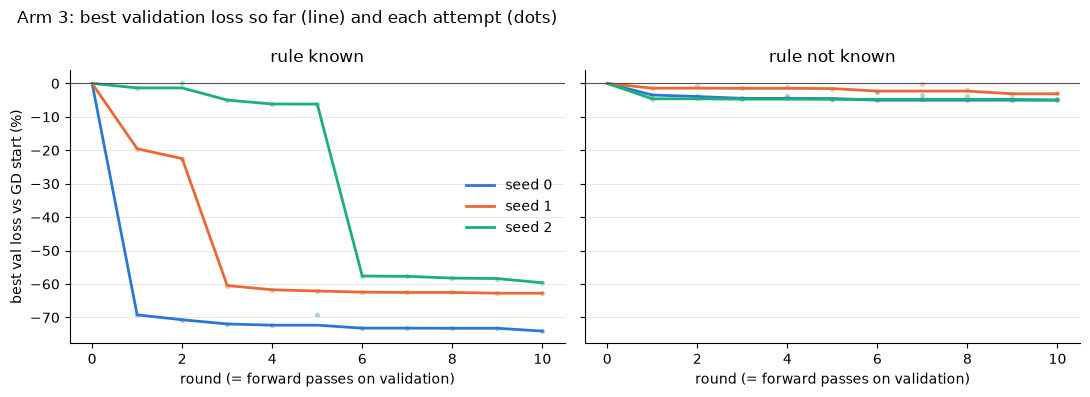

In [10]:
SEED_COLORS = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (c, runs) in zip(axes, arm3.items()):
    for s, r in runs.items():
        rel = lambda x: 100 * (x / gd[s]["val"]["loss"] - 1)
        tried = [(h["round"], rel(h["val"]["loss"])) for h in r["history"] if h["val"]]
        if tried:
            ax.scatter(*zip(*tried), s=14, color=SEED_COLORS[s], alpha=0.4, linewidths=0)
        ax.plot(range(len(r["best_curve"])), [rel(x) for x in r["best_curve"]], color=SEED_COLORS[s], lw=2, label=f"seed {s}")
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set(title=c, xlabel="round (= forward passes on validation)")
    ax.grid(axis="y", color="#e6e5e0", lw=0.6); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("best val loss vs GD start (%)"); axes[0].legend(frameon=False)
fig.suptitle("Arm 3: best validation loss so far (line) and each attempt (dots)", x=0.02, ha="left"); plt.tight_layout()

**What the LLM did, round by round** (its own one-line notes; `changed` = weights set that round, 513 = the whole network rewritten):

In [11]:
for c, runs in arm3.items():
    for s, r in runs.items():
        print(f"{c}, seed {s}")
        for h in r["history"]:
            v = f'{h["val"]["loss"]:.4f}' if h["val"] else "invalid"
            print(f'  {h["round"]:2d}  changed={h["n_changed"]:3d}  val_loss={v}  {(h["note"] or h["error"])[:95]}')

rule known, seed 0
   1  changed=451  val_loss=0.1167  Hand-built rule net: unit0 linear part, unit1 relu(anneal-1), units2-13 imp*cool via squared-di
   2  changed= 15  val_loss=0.1112  Rescale logit from 2.2x to 2.5x true logit (sharper calibration); W2 and b2 scaled by 2.5/2.2, 
   3  changed= 15  val_loss=0.1064  Rescale logit from 2.5x to 3.0x true logit (all W2 and b2 times 1.2), boundary unchanged
   4  changed= 15  val_loss=0.1050  Rescale logit from 3.0x to 3.5x true logit (all W2 and b2 times 7/6), boundary unchanged
   5  changed= 56  val_loss=0.1170  Denoise inputs: replace each relevant _mean weight w with 0.9089*w on _mean plus 0.0905*w on _p
   6  changed= 34  val_loss=0.1017  Smooth anneal hinge for measurement noise: split relu(x3-1)*12.25 into 6.125*relu(x3-0.89) (uni
   7  changed= 36  val_loss=0.1017  3-point Gauss-Hermite smoothing of anneal hinge (sigma=0.15): hinges at 0.751/1.01/1.269 with W
   8  changed= 16  val_loss=0.1015  Rescale logit from 3.5x to 3.75x tr

### 4.7 Temperature scaling

One temperature per final model, fitted on validation log loss. T > 1 means the model was overconfident.

In [12]:
final = {"1. GD": {s: gd[s]["weights"] for s in SEEDS}}
for c in CONDITIONS:
    final[f"2. AI from scratch | {c}"] = {r["trial"]: r["weights"] for r in arm2[c]}
    final[f"3. GD → AI tweak | {c}"] = {s: r["weights"] for s, r in arm3[c].items()}
ts = {arm: {s: temperature_scale(w, d.X_val, d.y_val) for s, w in ws.items()} for arm, ws in final.items()}
pd.DataFrame({arm: {s: t for s, (_, t) in v.items()} for arm, v in ts.items()}).T.add_prefix("T, seed/trial ")

,"T, seed/trial 0","T, seed/trial 1","T, seed/trial 2"
1. GD,1.416,1.205,1.405
2. AI from scratch | rule known,0.212,0.210,0.665
3. GD → AI tweak | rule known,0.966,1.003,0.974
2. AI from scratch | rule not known,1.979,2.038,2.276
3. GD → AI tweak | rule not known,0.924,0.982,1.017


## 5. Results

### 5.1 The single test-set evaluation

Everything above used training and validation data only. This cell scores every final model on the test set, **once**.

In [13]:
def score(p):
    return {"loss": log_loss(d.y_test, np.clip(p, 1e-7, 1 - 1e-7)), "acc": accuracy_score(d.y_test, p >= .5),
            "f1": f1_score(d.y_test, p >= .5, zero_division=0), "auc": roc_auc_score(d.y_test, p) if np.unique(p).size > 1 else 0.5}

lr = LogisticRegression(max_iter=5000).fit(d.X_train, d.y_train)
rows = [{"arm": "Always predict 'passes'", "seed": 0, **score(np.full(len(d.y_test), 1e-7)), "loss": np.nan},
        {"arm": "Logistic regression", "seed": 0, **score(lr.predict_proba(d.X_test)[:, 1])}]
for arm, ws in final.items():
    for s, w in ws.items():
        rows.append({"arm": arm, "seed": s, **metrics(w, d.X_test, d.y_test)})
        rows.append({"arm": arm + " + TS", "seed": s, **metrics(ts[arm][s][0], d.X_test, d.y_test)})
test = pd.DataFrame(rows)

ORDER = ["Always predict 'passes'", "Logistic regression", "1. GD", "1. GD + TS"] + [
    f"{a} | {c}{x}" for c in CONDITIONS for a in ("2. AI from scratch", "3. GD → AI tweak") for x in ("", " + TS")]
fmt = lambda x: f"{x.mean():.3f} ± {x.std():.3f}" if len(x) > 1 else f"{x.mean():.3f}"
summary = test.groupby("arm")[["acc", "f1", "auc", "loss"]].agg(fmt).add_prefix("test ").loc[ORDER]
summary

,test acc,test f1,test auc,test loss
arm,,,,
Always predict 'passes',0.667,0.000,0.500,nan
Logistic regression,0.746,0.580,0.764,0.602
1. GD,0.792 ± 0.018,0.654 ± 0.032,0.814 ± 0.014,0.628 ± 0.071
1. GD + TS,0.792 ± 0.018,0.654 ± 0.032,0.814 ± 0.014,0.547 ± 0.037
2. AI from scratch | rule known,0.930 ± 0.000,0.892 ± 0.000,0.983 ± 0.001,0.212 ± 0.044
2. AI from scratch | rule known + TS,0.930 ± 0.000,0.892 ± 0.000,0.983 ± 0.001,0.187 ± 0.016
3. GD → AI tweak | rule known,0.924 ± 0.005,0.878 ± 0.009,0.986 ± 0.002,0.163 ± 0.009
3. GD → AI tweak | rule known + TS,0.924 ± 0.005,0.878 ± 0.009,0.986 ± 0.002,0.164 ± 0.010
2. AI from scratch | rule not known,0.646 ± 0.018,0.560 ± 0.015,0.722 ± 0.018,0.773 ± 0.010


### 5.2 LLM cost per run (list-price equivalent, not billed)

In [14]:
cost = pd.DataFrame(
    [{"arm": f"2. AI from scratch | {c}", "out_tokens": r["output_tokens"], "cost_usd": r["cost_usd"], "wall_s": r["wall_s"]}
     for c in CONDITIONS for r in arm2[c]] +
    [{"arm": f"3. GD → AI tweak | {c}", "out_tokens": r["output_tokens"], "cost_usd": r["cost_usd"], "wall_s": r["wall_s"]}
     for c in CONDITIONS for r in arm3[c].values()])
cost.groupby("arm", sort=False).mean().round(2)

,out_tokens,cost_usd,wall_s
arm,,,
2. AI from scratch | rule known,5211.33,0.11,47.34
2. AI from scratch | rule not known,3296.00,0.07,29.55
3. GD → AI tweak | rule known,66182.67,1.68,616.76
3. GD → AI tweak | rule not known,19031.67,0.76,207.79


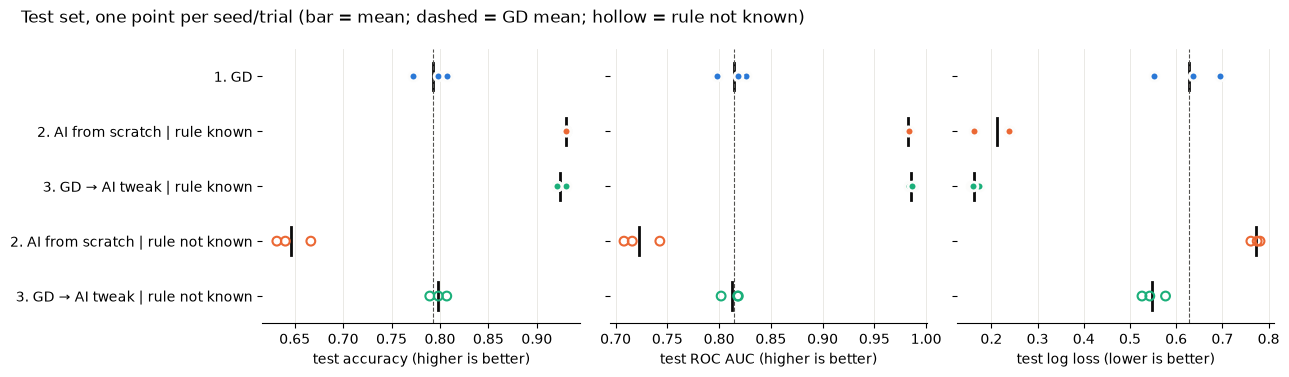

In [15]:
ARMS = ["1. GD"] + [f"{a} | {c}" for c in CONDITIONS for a in ("2. AI from scratch", "3. GD → AI tweak")]
COLORS = {"1. GD": "#2a78d6", "2. AI from scratch": "#eb6834", "3. GD → AI tweak": "#1baf7a"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, metric, label in zip(axes, ("acc", "auc", "loss"), ("accuracy (higher is better)", "ROC AUC (higher is better)", "log loss (lower is better)")):
    for y, arm in enumerate(ARMS):
        color, hollow = COLORS[arm.split(" | ")[0]], "not known" in arm
        v = test.loc[test.arm == arm, metric]
        ax.scatter(v, [y] * len(v), s=40, facecolors="none" if hollow else color,
                   edgecolors=color if hollow else "#fcfcfb", linewidths=1.5 if hollow else 2, zorder=3)
        ax.plot([v.mean()] * 2, [y - 0.25, y + 0.25], color="#0b0b0b", lw=2)
    ref = test.loc[test.arm == "1. GD", metric].mean()
    ax.axvline(ref, color="#52514e", lw=0.8, ls="--")
    ax.set(xlabel=f"test {label}"); ax.grid(axis="x", color="#e6e5e0", lw=0.6)
    ax.spines[["top", "right", "left"]].set_visible(False)
axes[0].set_yticks(range(len(ARMS)), ARMS); axes[0].set_ylim(len(ARMS) - 0.5, -0.5)
fig.suptitle("Test set, one point per seed/trial (bar = mean; dashed = GD mean; hollow = rule not known)", x=0.02, ha="left")
plt.tight_layout()

### 5.3 What arm 3 did to each GD model (test set, same seed)

In [16]:
gain = []
for s in SEEDS:
    g = metrics(gd[s]["weights"], d.X_test, d.y_test)
    g_ts = metrics(ts["1. GD"][s][0], d.X_test, d.y_test)
    for c in CONDITIONS:
        a = metrics(arm3[c][s]["weights"], d.X_test, d.y_test)
        gain.append({"seed": s, "condition": c,
                     "acc GD → AI": f'{g["acc"]:.3f} → {a["acc"]:.3f}',
                     "auc GD → AI": f'{g["auc"]:.3f} → {a["auc"]:.3f}',
                     "loss GD → AI": f'{g["loss"]:.3f} → {a["loss"]:.3f}',
                     "Δ loss vs GD %": 100 * (a["loss"] / g["loss"] - 1),
                     "Δ loss vs GD + TS %": 100 * (a["loss"] / g_ts["loss"] - 1),
                     "weights changed": arm3[c][s]["n_changed_total"]})
pd.DataFrame(gain).set_index(["condition", "seed"]).sort_index().round(1)

acc GD → AI    auc GD → AI   loss GD → AI  \
condition      seed                                                
rule known     0     0.772 → 0.921  0.798 → 0.984  0.694 → 0.174   
               1     0.798 → 0.930  0.826 → 0.987  0.553 → 0.156   
               2     0.807 → 0.921  0.818 → 0.986  0.636 → 0.160   
rule not known 0     0.772 → 0.789  0.798 → 0.802  0.694 → 0.577   
               1     0.798 → 0.798  0.826 → 0.818  0.553 → 0.526   
               2     0.807 → 0.807  0.818 → 0.819  0.636 → 0.543   

                     Δ loss vs GD %  Δ loss vs GD + TS %  weights changed  
condition      seed                                                        
rule known     0              -75.0                -70.4              482  
               1              -71.7                -69.7              513  
               2              -74.9                -70.4              513  
rule not known 0              -16.8                 -1.8               19  
               1               -4.8                  2.0               49  
               2              -14.7                  0.8               65

## 6. Conclusion

| Test set (mean ± std over 3) | Accuracy | AUC | Log loss | Log loss + TS |
|---|---|---|---|---|
| Always predict "passes" | 0.667 | 0.500 | – | – |
| Logistic regression | 0.746 | 0.764 | 0.602 | – |
| 1. GD | 0.792 ± 0.018 | 0.814 ± 0.014 | 0.628 ± 0.071 | 0.547 ± 0.037 |
| **Rule known** | | | | |
| 2. AI from scratch | 0.930 ± 0.000 | 0.983 ± 0.001 | 0.212 ± 0.044 | 0.187 ± 0.016 |
| 3. GD → AI tweak | **0.924 ± 0.005** | **0.986 ± 0.002** | **0.163 ± 0.009** | 0.164 ± 0.010 |
| **Rule not known** | | | | |
| 2. AI from scratch | 0.646 ± 0.018 | 0.722 ± 0.018 | 0.773 ± 0.010 | 0.650 ± 0.010 |
| 3. GD → AI tweak | 0.798 ± 0.009 | 0.813 ± 0.009 | 0.549 ± 0.026 | 0.554 ± 0.035 |

**1. With the rule known, the LLM wrote a classifier far better than GD, with no data.** All three from-scratch trials reached 0.93 test accuracy and 0.98 AUC, against 0.79 and 0.81 for GD trained on 341 rows. Its reasoning (section 4.5) compiles the rule straight into the network:
- It uses the clean `_mean` measurements.
- Two ReLU units carry the linear terms and one is the `anneal_temp` hinge.
- Twelve units approximate the `impurity × cooling` interaction as a difference of piecewise-linear squares.

The only thing it got wrong was the output scale. It was under-confident (fitted T ≈ 0.2), which one temperature fixes (log loss 0.212 → 0.187). This is the classifier version of the post's MinAtar result.

**2. With the rule known, editing a GD model turned into rebuilding it.** All three arm-3 runs eventually replaced the GD network with the rule network (482–513 of 513 weights changed). One did this in round 1; the other two first tried smaller edits (zeroing irrelevant features, temperature scaling) and rebuilt in round 3 and round 6. The remaining rounds were used for refinements a statistician would make:
- tuning the output scale;
- combining `_mean` and `_peak` with precision weights;
- smoothing the `anneal_temp` hinge for measurement noise.

On test this gave the best model in the study: accuracy 0.77–0.81 → 0.92–0.93 per seed, AUC 0.80–0.83 → 0.98–0.99, and log loss down 72–75% against GD and about 70% against GD + temperature scaling.

**3. With the rule not known, writing from scratch failed.** The weights scored 0.646 test accuracy, below always predicting "passes". From the feature names it guessed a plausible story: impurity and cooling raise failure, lattice density lowers it, and annealing has a U-shaped effect. Some of these directions were right, but it also gave weight to properties that don't matter. Guesses from names were not enough.

**4. With the rule not known, editing GD was only calibration.** The edits were temperature scaling, bias shifts and shrinking rows the LLM guessed were weak. Accuracy (0.792 → 0.798) and AUC (0.814 → 0.813) did not move. Log loss fell 12% against GD, but against GD + temperature scaling the change was −1.8%, +2.0% and +0.8% per seed. **Ten LLM rounds matched what one fitted number does.**

### Compared with the source post
| Claim in the post | This experiment |
|---|---|
| From rules alone, an LLM writes weights that beat a trained baseline (MinAtar vs PPO) | **Reproduced on a classifier:** from the rule alone, 0.93 vs 0.79 test accuracy for GD |
| Editing can fix a trained model | **Reproduced when the LLM has the knowledge:** with the rule, arm 3 raised every GD seed to about 0.92–0.93 accuracy |
| Editing cannot add an ability the model lacks | **Consistent:** without the rule, no accuracy or AUC gain, and no log-loss gain beyond temperature scaling |

### Scope
- The rule given was **exact** (true coefficients, threshold, interaction and measurement model), the strongest form of knowledge, like the post's source code.
- The data is synthetic in an invented domain, so the model cannot have seen it; validation and test have 114 rows each.
- Model: Claude Opus 5.5 (effort high) through headless Claude Code. Costs are list-price equivalents: about $0.11 per from-scratch reply and $1.68 per 10-round arm-3 run with the rule ($0.07 and $0.76 without it).

### Takeaway
Weight-space programming is a way to put **knowledge** into a network, not a way to learn from data. When an LLM knows how the data works, it can compile that into weights that beat gradient descent on a small dataset, in a single reply. When it doesn't, it can do no more than standard calibration. The practical recipe that worked best here: give the LLM the knowledge, let it write the network, then calibrate on validation.
